Epoch 1/3
860/860 ━━━━━━━━━━━━━━━━━━━━ 409s 462ms/step - accuracy: 0.8274 - loss: 0.4912 - val_accuracy: 0.8862 - val_loss: 0.3170
Epoch 2/3
860/860 ━━━━━━━━━━━━━━━━━━━━ 434s 453ms/step - accuracy: 0.8706 - loss: 0.3541 - val_accuracy: 0.8922 - val_loss: 0.2970
Epoch 3/3
860/860 ━━━━━━━━━━━━━━━━━━━━ 444s 456ms/step - accuracy: 0.8793 - loss: 0.3324 - val_accuracy: 0.8962 - val_loss: 0.2899
157/157 ━━━━━━━━━━━━━━━━━━━━ 61s 384ms/step
              precision    recall  f1-score   support

     T-shirt      0.813     0.863     0.837      1000
     Trouser      0.996     0.966     0.981      1000
    Pullover      0.789     0.867     0.826      1000
       Dress      0.878     0.866     0.872      1000
        Coat      0.773     0.835     0.803      1000
      Sandal      0.972     0.961     0.966      1000
       Shirt      0.730     0.574     0.643      1000
     Sneaker      0.927     0.967     0.947      1000
         Bag      0.972     0.986     0.979      1000
        Boot      0.97

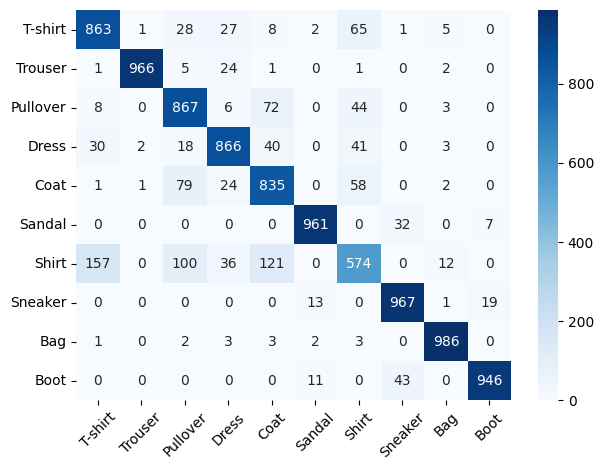

In [2]:

import tensorflow as tf, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix

(x,y),(xt,yt)=tf.keras.datasets.fashion_mnist.load_data()
names=['T-shirt','Trouser','Pullover','Dress','Coat','Sandal','Shirt','Sneaker','Bag','Boot']
def prep(x,y):
    x=tf.cast(x[...,None],tf.float32)
    x=tf.image.grayscale_to_rgb(x)
    x=tf.image.resize(x,(96,96))
    return tf.keras.applications.mobilenet_v2.preprocess_input(x),y
train=tf.data.Dataset.from_tensor_slices((x[5000:],y[5000:])).shuffle(5000).map(prep).batch(64).prefetch(1)
val=tf.data.Dataset.from_tensor_slices((x[:5000],y[:5000])).map(prep).batch(64)
test=tf.data.Dataset.from_tensor_slices((xt,yt)).map(prep).batch(64)

base=tf.keras.applications.MobileNetV2(input_shape=(96,96,3),include_top=False,weights='imagenet')
base.trainable=False
model=models.Sequential([layers.Input((96,96,3)),layers.RandomFlip('horizontal'),base,layers.GlobalAveragePooling2D(),layers.Dropout(.3),layers.Dense(10,activation='softmax')])
model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])
model.fit(train,validation_data=val,epochs=3,callbacks=[tf.keras.callbacks.EarlyStopping(patience=1,restore_best_weights=True)])
p=np.argmax(model.predict(test),axis=1)
print(classification_report(yt,p,target_names=names,digits=3))
sns.heatmap(confusion_matrix(yt,p),annot=True,fmt='d',cmap='Blues',xticklabels=names,yticklabels=names)
plt.xticks(rotation=45); plt.tight_layout(); plt.show()
